<a href="https://colab.research.google.com/github/20danaai/Learn_LibrariesPy/blob/main/03_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [172]:
import sklearn
from sklearn.datasets import make_circles

In [173]:
n_samples=1000
x,y=make_circles(n_samples,noise=0.05,random_state=42)

In [174]:
import pandas as pd
circles=pd.DataFrame({'x1':x[:,0],'x2':x[:,1],'label':y})
circles.head(10)

,x1,x2,label
0,0.742207,0.246686,1
1,-0.734032,0.168692,1
2,-0.829859,0.221959,1
3,-0.429136,0.672230,1
4,0.445602,-0.894936,0
5,-0.469885,0.708037,1
6,-0.016045,0.805623,1
7,0.759623,0.159526,1
8,-0.175692,-0.799837,1
9,-0.110616,1.042207,0


In [175]:
circles.label.value_counts()

,count
label,
1,500
0,500


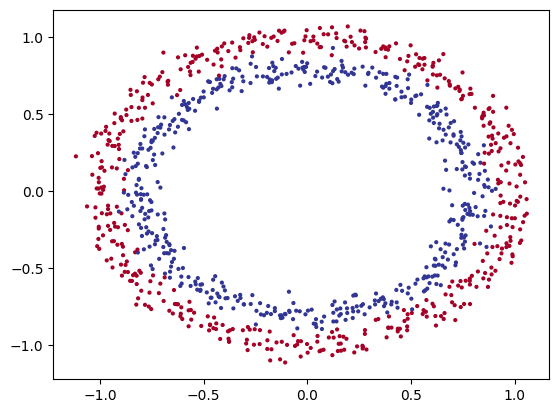

In [176]:

import matplotlib.pyplot as plt
plt.scatter(x=x[:,0],y=x[:,1],s=4,c=y,cmap=plt.cm.RdYlBu)


In [177]:
import torch
x=torch.from_numpy(x).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

In [178]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [179]:
import torch
from torch import nn
device='cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [180]:
class circlemodel_v0(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1=nn.Linear(2,5)
    self.layer2=nn.Linear(5,1)
  def forward(self,x:torch.tensor)->torch.tensor:
    return self.layer2(self.layer1(x))


In [181]:
model_0=circlemodel_v0().to(device)
model_0

circlemodel_v0(
  (layer1): Linear(in_features=2, out_features=5, bias=True)
  (layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [182]:
model_0=nn.Sequential(
    nn.Linear(2,5),
    nn.Linear(5,1)
)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [183]:
loss_fn=nn.BCEWithLogitsLoss()
optimizier=torch.optim.SGD(params=model_0.parameters(),lr=0.01)

In [184]:
def accuracy_fun(y_true,y_pred):
  correct=torch.eq(y_pred,y_true).sum().item()
  acc=(correct/len(y_pred))*100
  return acc

In [185]:
x_true=torch.tensor([1,0,1,0,1,1])
x_pred=torch.tensor([1,0,1,1,1,1])
accuracy_fun(y_true=x_true,y_pred=x_pred)

83.33333333333334

In [186]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

In [187]:
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)

In [188]:
epochs=30
device='cuda' if torch.cuda.is_available() else 'cpu'
model_0.to(device)
for epoch in range(epochs):
  model_0.train()
  y_logits=model_0(x_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))
  print(y_logits.shape,y_train.shape)
  loss=loss_fn(y_logits,y_train)
  acc=accuracy_fun(y_true=y_train,y_pred=y_pred)
  optimizier.zero_grad()
  loss.backward()
  optimizier.step()
  model_0.eval()
  with torch.inference_mode():
    test_legist=model_0(x_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_legist))
    test_loss=loss_fn(test_legist,y_test)
    test_acc=accuracy_fun(y_true=y_test,y_pred=test_pred)
  if epochs %10==0:
    print(f'epoch : {epoch} | loss {loss:.5f} | Train Accuracy {acc:.5f} | Test loss : {test_loss:.5f} | Test acc :{test_acc:.5f}')


torch.Size([800]) torch.Size([800])
epoch : 0 | loss 0.70172 | Train Accuracy 50.00000 | Test loss : 0.70256 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 1 | loss 0.70166 | Train Accuracy 50.00000 | Test loss : 0.70249 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 2 | loss 0.70160 | Train Accuracy 50.00000 | Test loss : 0.70243 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 3 | loss 0.70155 | Train Accuracy 50.00000 | Test loss : 0.70238 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 4 | loss 0.70149 | Train Accuracy 50.00000 | Test loss : 0.70232 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 5 | loss 0.70143 | Train Accuracy 50.00000 | Test loss : 0.70226 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 6 | loss 0.70138 | Train Accuracy 50.00000 | Test loss : 0.70220 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
epoch : 7 | loss 0.70132 | Train Accuracy 50.00000 | T

In [189]:
import requests
from pathlib import Path

In [190]:
utills_dire=Path('utills')
utills_dire.mkdir(parents=True,exist_ok=True)
if Path('helper_functions.py').is_file():
  print('helper_functions.py already exists, skipping download')
else:

  print("Downloading helper_functions.py")
  request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open (utills_dire/'helper_functions.py','wb') as f:
    f.write(request.content)
from utills.helper_functions import plot_predictions, plot_decision_boundary

In [191]:
import importlib
import utills.helper_functions as hf

importlib.reload(hf)

from utills.helper_functions import plot_predictions, plot_decision_boundary

In [192]:
print(hf.plot_predictions)
print(hf.plot_decision_boundary)

<function plot_predictions at 0x7de4e2d4d080>
<function plot_decision_boundary at 0x7de4e2c8f1a0>


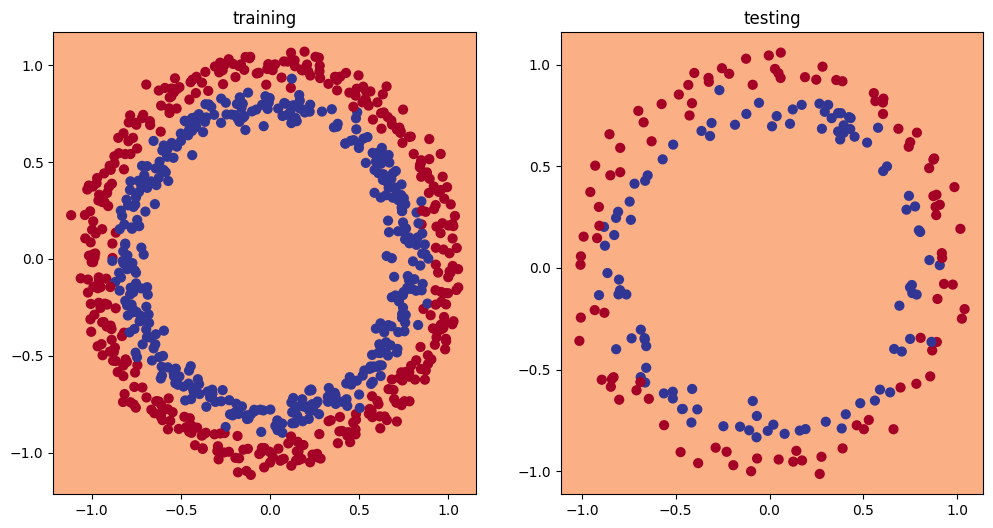

In [193]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('training')
plot_decision_boundary(model_0,x_train,y_train)
plt.subplot(1,2,2)
plt.title('testing')
plot_decision_boundary(model_0,x_test,y_test)

In [194]:
class circlev2(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer1=nn.Linear(2,10)
    self.layer2=nn.Linear(10,10)
    self.layer3=nn.Linear(10,1)
    self.relu=nn.ReLU()
  def forward(self,x: torch.tensor)-> torch.tensor:
    return self.relu(self.layer3(self.relu(self.layer2(self.relu(self.layer1(x))))))
model_1=circlev2().to(device)





In [195]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [196]:
loss=nn.BCEWithLogitsLoss()
optimizier=torch.optim.SGD(params=model_1.parameters(),lr=0.1)

In [197]:
x_train,y_train=x_train.to(device),y_train.to(device)
x_test,y_test=x_test.to(device),y_test.to(device)

In [200]:
epochs=50
device='cuda' if torch.cuda.is_available() else 'cpu'
model_1.to(device)
for epoch in range(epochs):
  model_1.train()
  y_logits=model_1(x_train).squeeze()
  y_pred=torch.round(torch.sigmoid(y_logits))
  print(y_logits.shape,y_train.shape)
  loss=loss_fn(y_logits,y_train)
  acc=accuracy_fun(y_true=y_train,y_pred=y_pred)
  optimizier.zero_grad()
  loss.backward()
  optimizier.step()
  model_1.eval()
  with torch.inference_mode():
    test_legist=model_1(x_test).squeeze()
    test_pred=torch.round(torch.sigmoid(test_legist))
    test_loss=loss_fn(test_legist,y_test)
    test_acc=accuracy_fun(y_true=y_test,y_pred=test_pred)
  if epoch %10==0:
    print(f'epoch : {epoch} | loss {loss:.5f} | Train Accuracy {acc:.5f} | Test loss : {test_loss:.5f} | Test acc :{test_acc:.5f}')

torch.Size([800]) torch.Size([800])
epoch : 0 | loss 0.69194 | Train Accuracy 51.37500 | Test loss : 0.69203 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
epoch : 10 | loss 0.69182 | Train Accuracy 51.37500 | Test loss : 0.69192 | Test acc :50.00000
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
torch.Size([800]) torch.Size([800])
epoch : 20 | loss 0.69171 | Train Accuracy 51.37500 | T

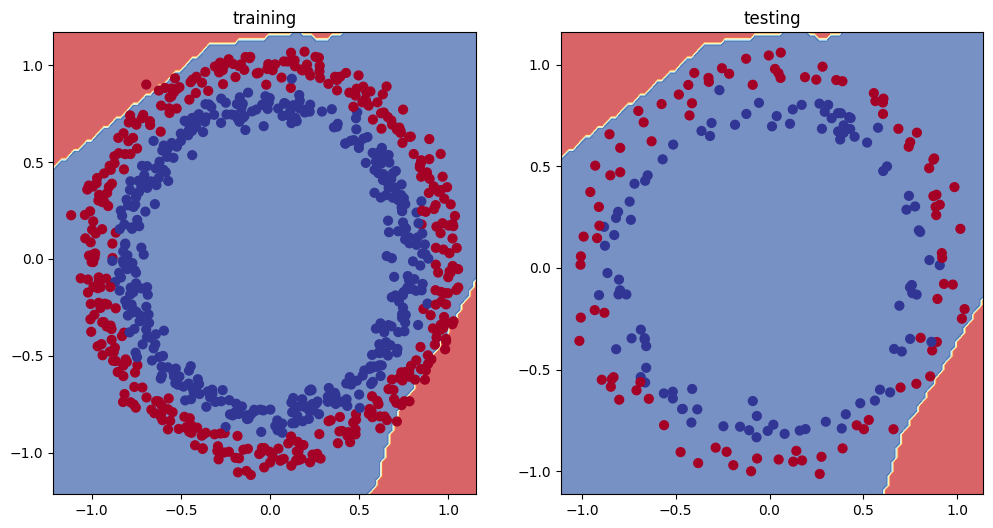

In [199]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('training')
plot_decision_boundary(model_1,x_train,y_train)
plt.subplot(1,2,2)
plt.title('testing')
plot_decision_boundary(model_1,x_test,y_test)

In [201]:
def relu(x):
  return torch.max(torch.tensor(0),x)
x=torch.linspace(-15,15,100)
y=relu(x)
y

tensor([ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.1515,  0.4545,  0.7576,  1.0606,  1.3636,  1.6667,
         1.9697,  2.2727,  2.5758,  2.8788,  3.1818,  3.4848,  3.7879,  4.0909,
         4.3939,  4.6970,  5.0000,  5.3030,  5.6061,  5.9091,  6.2121,  6.5152,
         6.8182,  7.1212,  7.4242,  7.7273,  8.0303,  8.3333,  8.6364,  8.9394,
         9.2424,  9.5455,  9.8485, 10.1515, 10.4545, 10.7576, 11.0606, 11.3636,
        11.6667, 11.9697, 12.2727, 12.5758, 12.8788, 13.1818, 13.4848, 13.7879,
        14.0909, 14.3939, 14.6970, 15.00

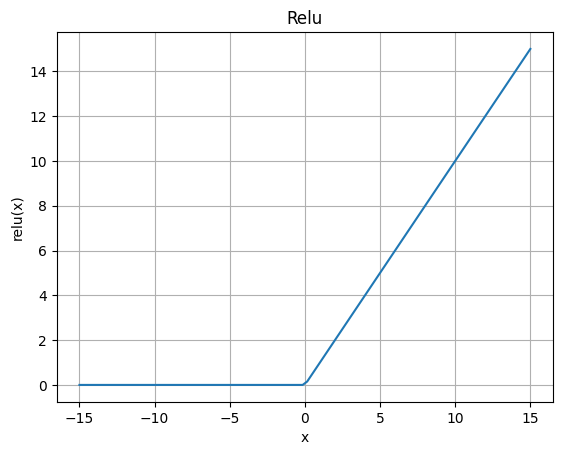

In [203]:
plt.plot(x.numpy(),y.numpy())
plt.title('Relu')
plt.xlabel('x')
plt.ylabel('relu(x)')
plt.grid(True)
plt.show()

In [206]:
def tanh(x):
  return (torch.exp(x)-torch.exp(-x))/(torch.exp(x)+torch.exp(-x))
x=torch.linspace(-15,15,100)
y=tanh(x)
y


tensor([-1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000, -1.0000,
        -1.0000, -0.9999, -0.9998, -0.9997, -0.9994, -0.9990, -0.9981, -0.9966,
        -0.9937, -0.9885, -0.9790, -0.9618, -0.9311, -0.8772, -0.7859, -0.6396,
        -0.4256, -0.1504,  0.1504,  0.4256,  0.6396,  0.7859,  0.8772,  0.9311,
         0.9618,  0.9790,  0.9885,  0.9937,  0.9966,  0.9981,  0.9990,  0.9994,
         0.9997,  0.9998,  0.9999,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,
         1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,
         1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,
         1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,
         1.0000,  1.0000,  1.0000,  1.00

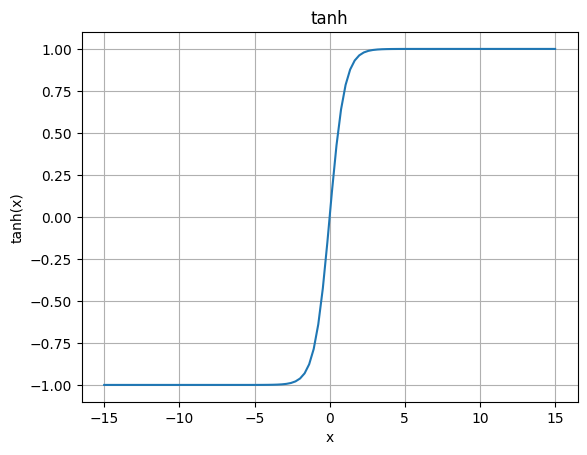

In [208]:
plt.plot(x.numpy(),y.numpy())
plt.title('tanh')
plt.xlabel('x')
plt.ylabel('tanh(x)')
plt.grid(True)
plt.show()

In [211]:
def sigmoid(x):
  return 1/(1+torch.exp(-x))
x=torch.linspace(-15,15,100)
y=sigmoid(x)
y

tensor([3.0590e-07, 4.1418e-07, 5.6078e-07, 7.5927e-07, 1.0280e-06, 1.3919e-06,
        1.8846e-06, 2.5516e-06, 3.4547e-06, 4.6776e-06, 6.3332e-06, 8.5749e-06,
        1.1610e-05, 1.5719e-05, 2.1283e-05, 2.8816e-05, 3.9015e-05, 5.2824e-05,
        7.1521e-05, 9.6833e-05, 1.3110e-04, 1.7750e-04, 2.4031e-04, 3.2534e-04,
        4.4045e-04, 5.9626e-04, 8.0714e-04, 1.0925e-03, 1.4786e-03, 2.0010e-03,
        2.7073e-03, 3.6621e-03, 4.9518e-03, 6.6929e-03, 9.0404e-03, 1.2201e-02,
        1.6449e-02, 2.2142e-02, 2.9746e-02, 3.9856e-02, 5.3212e-02, 7.0715e-02,
        9.3407e-02, 1.2242e-01, 1.5887e-01, 2.0365e-01, 2.5719e-01, 3.1917e-01,
        3.8828e-01, 4.6219e-01, 5.3781e-01, 6.1172e-01, 6.8083e-01, 7.4281e-01,
        7.9635e-01, 8.4113e-01, 8.7758e-01, 9.0659e-01, 9.2928e-01, 9.4679e-01,
        9.6014e-01, 9.7025e-01, 9.7786e-01, 9.8355e-01, 9.8780e-01, 9.9096e-01,
        9.9331e-01, 9.9505e-01, 9.9634e-01, 9.9729e-01, 9.9800e-01, 9.9852e-01,
        9.9891e-01, 9.9919e-01, 9.9940e-

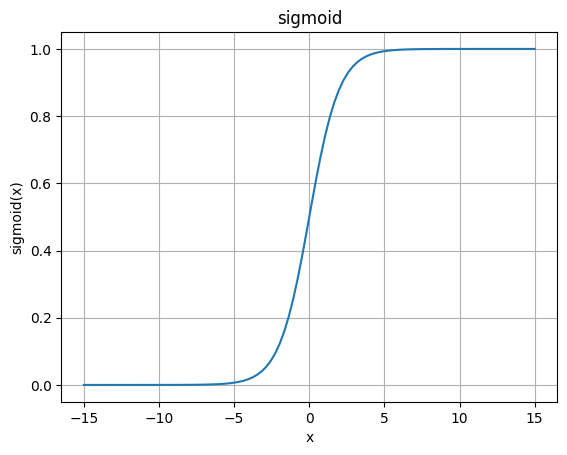

In [212]:
plt.plot(x.numpy(),y.numpy())
plt.title('sigmoid')
plt.xlabel('x')
plt.ylabel('sigmoid(x)')
plt.grid(True)
plt.show()